# 01 — Neural Network From Scratch

A neural network built with NumPy only: neurons, activations, the forward pass, the loss, backpropagation and training.
At the end, the same network in PyTorch, which is how it is done in practice.

## What's in this notebook

- 1\. What is a neural network?
- 2\. The data: a spiral no straight line can split
- 3\. Why we need non-linear activations
- 4\. Activation functions
- 5\. The forward pass
- 6\. Loss functions
- 7\. Backpropagation
- 8\. Gradient checking
- 9\. Training with mini-batch gradient descent
- 10\. The learning rate
- 11\. Weight initialization
- 12\. How wide and how deep?
- 13\. The same network in PyTorch
- 14\. Trade-offs
- 15\. Interview questions
- 16\. In my own words

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# 1. WHAT IS A NEURAL NETWORK?

- A **neuron** computes a weighted sum of its inputs plus a bias, then applies an activation function: `a = f(w·x + b)`.
  Logistic regression is exactly one neuron with a sigmoid activation.
- A **layer** is many neurons side by side. For a batch of rows it is one matrix multiply: `Z = X·W + b`.
- A **network** stacks layers: each layer's output is the next layer's input. Hidden layers learn new features from the raw inputs;
  the last layer turns them into a prediction. "Deep" means many hidden layers.

The network in this notebook:

```text
input (2 numbers)     hidden layer (64 neurons, ReLU)      output (3 neurons, softmax)

   x1 ──┐                                                ┌──  P(class 0)
        ├────────►   h1  h2  h3  ...  h64   ────────────►├──  P(class 1)
   x2 ──┘                                                └──  P(class 2)

parameters:  W1 (2 × 64) + b1 (64) + W2 (64 × 3) + b2 (3)  =  387 numbers learned by training
```

A layer with `n_in` inputs and `n_out` neurons has `n_in · n_out` weights and `n_out` biases.

# 2. THE DATA: A SPIRAL NO STRAIGHT LINE CAN SPLIT

Three classes wound around each other. A linear model can only draw straight boundaries, so it should fail here.

train (675, 2), test (225, 2), classes [300 300 300]
logistic regression: train 0.524, test 0.520


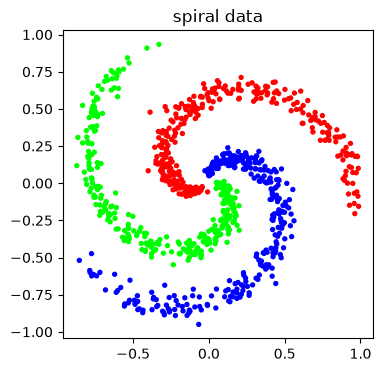

In [2]:
def make_spiral(n_per_class: int = 300, n_classes: int = 3, noise: float = 0.2, seed: int = 0):
    """Points on interleaved spiral arms, one arm per class."""
    rng = np.random.default_rng(seed)
    X, y = [], []
    for k in range(n_classes):
        radius = np.linspace(0.05, 1, n_per_class)
        angle = np.linspace(k * 4, (k + 1) * 4, n_per_class) + rng.normal(0, noise, n_per_class)
        X.append(np.c_[radius * np.sin(angle), radius * np.cos(angle)])
        y.append(np.full(n_per_class, k))
    return np.vstack(X), np.concatenate(y)


X, y = make_spiral()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print(f"train {X_train.shape}, test {X_test.shape}, classes {np.bincount(y)}")

linear = LogisticRegression().fit(X_train, y_train)
print(f"logistic regression: train {linear.score(X_train, y_train):.3f}, test {linear.score(X_test, y_test):.3f}")

plt.figure(figsize=(4, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="brg", s=8)
plt.title("spiral data")
plt.show()

Logistic regression scores 0.524 on train and 0.520 on test, not much better than guessing (0.333 for 3 classes).
Its boundaries are straight lines, and no straight line separates spiral arms.

# 3. WHY WE NEED NON-LINEAR ACTIVATIONS

Without an activation function, stacking layers is pointless: two linear layers are one linear layer,
because `(X·W1)·W2 = X·(W1·W2)`. The network could still only draw straight boundaries.

The classic example is **XOR**: output 1 when exactly one input is 1. No single straight line separates the 1s from the 0s,
so one neuron (a perceptron, or logistic regression) can't learn it. Two hidden ReLU neurons can:
`h1 = ReLU(x1 + x2)`, `h2 = ReLU(x1 + x2 − 1)`, output `= h1 − 2·h2`.

In [3]:
def relu(z):
    return np.maximum(0, z)


# Two linear layers with no activation collapse into one
W1, W2 = np.random.default_rng(0).normal(size=(2, 4)), np.random.default_rng(1).normal(size=(4, 3))
print("max difference between X·W1·W2 and X·(W1·W2):", np.abs(X[:5] @ W1 @ W2 - X[:5] @ (W1 @ W2)).max())

# XOR with two hand-set ReLU neurons
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
hidden = relu(X_xor @ np.array([[1, 1], [1, 1]]) + np.array([0, -1]))
print("XOR inputs:", X_xor.tolist(), " network output:", (hidden @ np.array([1, -2])).tolist())

max difference between X·W1·W2 and X·(W1·W2): 2.7755575615628914e-17
XOR inputs: [[0, 0], [0, 1], [1, 0], [1, 1]]  network output: [0, 1, 1, 0]


The two products differ only by floating-point rounding (about 1e-17), so the second linear layer added nothing.
With one ReLU in between, the network outputs exactly XOR: 0, 1, 1, 0.

# 4. ACTIVATION FUNCTIONS

| Function | Formula | Output range | Where it is used |
|---|---|---|---|
| sigmoid | 1 / (1 + e^−z) | (0, 1) | binary output layer, gates inside LSTMs |
| tanh | (e^z − e^−z) / (e^z + e^−z) | (−1, 1) | RNNs; zero-centred, unlike sigmoid |
| ReLU | max(0, z) | [0, ∞) | the default for hidden layers in MLPs and CNNs |
| Leaky ReLU | z if z > 0, else 0.01·z | (−∞, ∞) | avoids dead ReLUs |
| GELU | z · Φ(z), Φ = normal CDF | about (−0.17, ∞) | transformers (BERT, GPT) |
| SiLU / Swish | z · sigmoid(z) | about (−0.28, ∞) | LLaMA-style LLMs (inside SwiGLU) |
| softmax | e^zᵢ / Σⱼ e^zⱼ | (0, 1), the row sums to 1 | multi-class output layer |

- **Saturation and vanishing gradients:** sigmoid and tanh flatten out for large |z|, where their derivative is close to 0.
  Backprop multiplies one derivative per layer, so many sigmoid layers shrink the gradient towards 0 and the early layers stop learning.
- **ReLU** has derivative 1 for every z > 0, so the gradient passes through unchanged, and it is cheap to compute.
- **Dead ReLU:** a neuron whose input is negative for every training row outputs 0 and gets zero gradient, so it never recovers.
  A learning rate that is too high often causes it. Leaky ReLU and GELU keep a small gradient for z < 0.
- **Softmax** is computed after subtracting the row maximum. The result is the same, but `e^z` can't overflow.

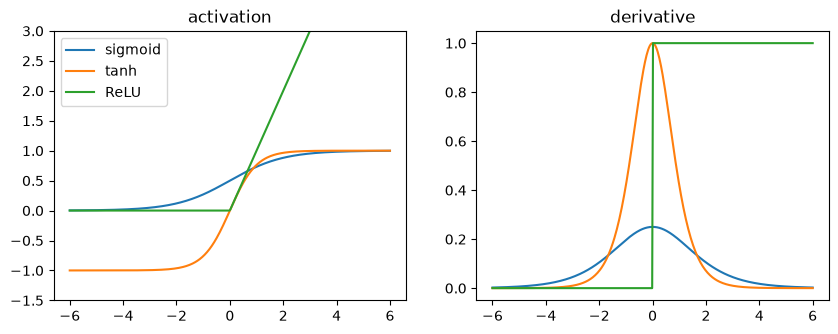

largest sigmoid derivative: 0.25
gradient factor after 10 sigmoid layers, at best: 0.25 ** 10 = 9.5367431640625e-07


In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)        # same result, no overflow
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


z = np.linspace(-6, 6, 400)
functions = {"sigmoid": sigmoid(z), "tanh": np.tanh(z), "ReLU": relu(z)}
derivatives = {"sigmoid": sigmoid(z) * (1 - sigmoid(z)), "tanh": 1 - np.tanh(z) ** 2, "ReLU": (z > 0).astype(float)}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name in functions:
    axes[0].plot(z, functions[name], label=name)
    axes[1].plot(z, derivatives[name], label=name)
axes[0].set(title="activation", ylim=(-1.5, 3))
axes[1].set(title="derivative")
axes[0].legend()
plt.show()

print("largest sigmoid derivative:", derivatives["sigmoid"].max().round(3))
print("gradient factor after 10 sigmoid layers, at best: 0.25 ** 10 =", 0.25 ** 10)

The sigmoid derivative is never more than 0.25. Through 10 sigmoid layers the gradient shrinks by at least 0.25¹⁰ ≈ 1e-6,
which is the vanishing gradient problem in one number. ReLU's derivative is exactly 1 on the positive side.

# 5. THE FORWARD PASS

For a batch of n rows, the network in section 1 computes:

```text
Z1 = X · W1 + b1        (n × 64)
A1 = ReLU(Z1)           (n × 64)
Z2 = A1 · W2 + b2       (n × 3)     the raw scores, called "logits"
P  = softmax(Z2)        (n × 3)     class probabilities, each row sums to 1
```

The prediction is the class with the highest probability. Writing the shape next to each line catches most bugs:
an (n × 2) input times a (2 × 64) weight matrix gives (n × 64).

# 6. LOSS FUNCTIONS

| Task | Output layer | Loss |
|---|---|---|
| regression | 1 unit, no activation | MSE (or MAE, Huber) |
| binary classification | 1 unit + sigmoid | binary cross-entropy |
| multi-class classification | K units + softmax | categorical cross-entropy |

Cross-entropy for one row is `−log(probability given to the true class)`, averaged over the rows:
being confident and right costs almost nothing, being confident and wrong costs a lot.

**Why not MSE for classification?** With a sigmoid output, the MSE gradient is `(p − y) · p(1 − p)`.
When the model is confidently wrong (p ≈ 0 but y = 1), `p(1 − p)` is close to 0, so it barely learns from its worst mistakes.
The cross-entropy gradient is just `p − y`. (The ML repo covers this for logistic regression.)

A sanity check: before training, a 3-class model should predict about 1/3 for every class, so its loss should be close to −log(1/3) = 1.099.

In [5]:
for p in [0.99, 0.9, 0.5, 0.1, 0.01]:
    print(f"true class given p = {p:<5} ->  loss = {-np.log(p):.3f}")
print(f"\nrandom guess over 3 classes: -log(1/3) = {-np.log(1 / 3):.3f}")

true class given p = 0.99  ->  loss = 0.010
true class given p = 0.9   ->  loss = 0.105
true class given p = 0.5   ->  loss = 0.693
true class given p = 0.1   ->  loss = 2.303
true class given p = 0.01  ->  loss = 4.605

random guess over 3 classes: -log(1/3) = 1.099


p = 0.9 costs 0.105, p = 0.1 costs 2.303 and p = 0.01 costs 4.605: the loss grows fast as the model becomes confidently wrong.

# 7. BACKPROPAGATION

Training needs the gradient of the loss with respect to every weight. **Backpropagation** gets all of them in one backward pass
with the chain rule: start from the loss, walk back through the forward pass, and at each step multiply the incoming gradient
by the local derivative of that step. The forward pass saves Z1, A1 and P because the backward pass needs them.

For our network (Y = the labels as one-hot rows, n = batch size):

```text
dZ2 = (P − Y) / n                   softmax + cross-entropy together give just "prediction − truth"
dW2 = A1ᵀ · dZ2                     db2 = dZ2 summed over the rows
dA1 = dZ2 · W2ᵀ                     send the gradient back through W2
dZ1 = dA1 ⊙ ReLU'(Z1)               ReLU'(z) = 1 if z > 0, else 0  (⊙ = element-wise)
dW1 = Xᵀ · dZ1                      db1 = dZ1 summed over the rows
```

Every gradient has the same shape as its parameter (dW1 is 2 × 64, like W1). Then gradient descent updates each one:
`W ← W − learning_rate · dW`.

Why `P − Y`: for softmax followed by cross-entropy, the derivative of the loss with respect to logit zᵢ is `pᵢ − 1` for the true class
and `pᵢ` for the others. The two formulas simplify into one.

In [6]:
class MLP:
    """Two-layer network: Linear -> ReLU -> Linear -> softmax, trained with cross-entropy."""

    def __init__(self, n_in: int, n_hidden: int, n_out: int, init: str | float = "he", seed: int = 0):
        rng = np.random.default_rng(seed)
        if init == "he":                     # He initialization, made for ReLU (section 11)
            self.W1 = rng.normal(0, np.sqrt(2 / n_in), (n_in, n_hidden))
            self.W2 = rng.normal(0, np.sqrt(2 / n_hidden), (n_hidden, n_out))
        else:                                # every weight set to the same constant (section 11)
            self.W1 = np.full((n_in, n_hidden), float(init))
            self.W2 = np.full((n_hidden, n_out), float(init))
        self.b1, self.b2 = np.zeros(n_hidden), np.zeros(n_out)

    def params(self) -> dict:
        return {"W1": self.W1, "b1": self.b1, "W2": self.W2, "b2": self.b2}

    def forward(self, X):
        self.X = X                           # saved for the backward pass
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = relu(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.P = softmax(self.Z2)
        return self.P

    def loss(self, y) -> float:
        return -np.log(self.P[np.arange(len(y)), y]).mean()

    def backward(self, y) -> dict:
        n = len(y)
        dZ2 = self.P.copy()
        dZ2[np.arange(n), y] -= 1            # P - Y, without building the one-hot matrix
        dZ2 /= n
        dZ1 = (dZ2 @ self.W2.T) * (self.Z1 > 0)
        return {"W1": self.X.T @ dZ1, "b1": dZ1.sum(axis=0), "W2": self.A1.T @ dZ2, "b2": dZ2.sum(axis=0)}

    def predict(self, X):
        return self.forward(X).argmax(axis=1)


model = MLP(2, 64, 3)
print("parameters:", sum(p.size for p in model.params().values()))
model.forward(X_train)
print(f"loss before training: {model.loss(y_train):.3f}")

parameters: 387
loss before training: 1.101


387 parameters, as counted in section 1. The loss before training is 1.101, close to the 1.099 of a random guess, so the setup looks right.

# 8. GRADIENT CHECKING

A hand-written backward pass is easy to get subtly wrong. **Gradient checking** compares it with a numerical estimate:
nudge one weight up and down by a tiny ε and measure how the loss changes:

```text
numerical gradient ≈ (loss(w + ε) − loss(w − ε)) / (2ε)
```

It needs two forward passes per weight, far too slow for training, but fine on a small model to test the code once.
A relative error around 1e-7 or below means the backward pass is right.

In [7]:
def gradient_check(model: MLP, X, y, eps: float = 1e-5) -> dict:
    model.forward(X)
    analytic = model.backward(y)
    errors = {}
    for name, param in model.params().items():
        numeric = np.zeros_like(param)
        for idx in np.ndindex(param.shape):
            original = param[idx]
            param[idx] = original + eps
            model.forward(X)
            loss_plus = model.loss(y)
            param[idx] = original - eps
            model.forward(X)
            loss_minus = model.loss(y)
            param[idx] = original
            numeric[idx] = (loss_plus - loss_minus) / (2 * eps)
        errors[name] = np.abs(numeric - analytic[name]).max() / np.abs(numeric).max()
    return errors


for name, err in gradient_check(MLP(2, 16, 3, seed=1), X_train[:20], y_train[:20]).items():
    print(f"{name}: relative error {err:.1e}")

W1: relative error 6.6e-10
b1: relative error 2.5e-10
W2: relative error 1.0e-10
b2: relative error 7.8e-11


All four relative errors are around 1e-10, so the backward pass in section 7 matches the numerical gradient.

# 9. TRAINING WITH MINI-BATCH GRADIENT DESCENT

| Term | Meaning |
|---|---|
| batch size | rows used for one gradient step (here 32) |
| iteration (step) | one forward pass, one backward pass and one weight update on one batch |
| epoch | one full pass over the training data (here 675 rows / 32 = 22 steps) |

| Variant | Rows per step | Trade-off |
|---|---|---|
| batch gradient descent | all of them | smooth, but slow and memory-hungry on big data |
| stochastic gradient descent (SGD) | 1 | fast steps, very noisy |
| mini-batch gradient descent | 32 to a few thousand | the standard: efficient on GPUs, and the noise helps escape bad regions |

In deep-learning code "SGD" usually means mini-batch. Shuffling every epoch keeps the batches different.

training loss after epoch 1, 10, 50, 100, 300: [0.62, 0.178, 0.046, 0.018, 0.005]
MLP: train 1.000, test 1.000


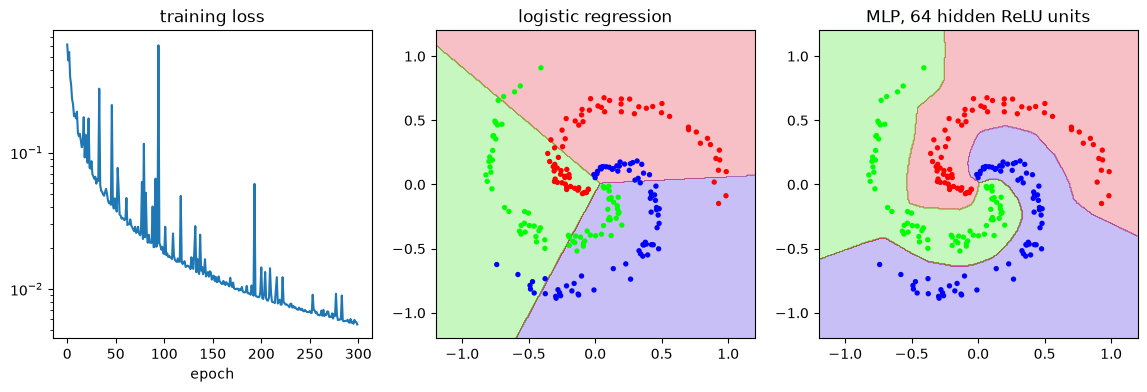

In [8]:
def train(model: MLP, X, y, epochs: int = 300, lr: float = 0.5, batch_size: int = 32, seed: int = 0) -> list:
    """Mini-batch gradient descent. Returns the training loss after each epoch."""
    rng = np.random.default_rng(seed)
    history = []
    for _ in range(epochs):
        order = rng.permutation(len(X))                  # shuffle every epoch
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            model.forward(X[batch])
            grads = model.backward(y[batch])
            for name, param in model.params().items():
                param -= lr * grads[name]                # gradient descent step, in place
        model.forward(X)
        history.append(model.loss(y))
    return history


def accuracy(model, X, y) -> float:
    return (model.predict(X) == y).mean()


model = MLP(2, 64, 3)
history = train(model, X_train, y_train)
print("training loss after epoch 1, 10, 50, 100, 300:", [round(float(history[i]), 3) for i in [0, 9, 49, 99, 299]])
print(f"MLP: train {accuracy(model, X_train, y_train):.3f}, test {accuracy(model, X_test, y_test):.3f}")


def plot_boundary(predict, ax, title):
    xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
    ax.contourf(xx, yy, predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape), alpha=0.25, cmap="brg")
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="brg", s=8)
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(history)
axes[0].set(title="training loss", xlabel="epoch", yscale="log")
plot_boundary(linear.predict, axes[1], "logistic regression")
plot_boundary(model.predict, axes[2], "MLP, 64 hidden ReLU units")
plt.show()

The loss falls from 0.620 after the first epoch to 0.005 after 300. The MLP scores 1.000 on the test set, against 0.520 for logistic regression:
the hidden layer learned curved boundaries that follow the spiral arms.

# 10. THE LEARNING RATE

The learning rate is the step size of gradient descent, and usually the most important hyperparameter to tune.

- too small: the loss falls slowly, and training needs many more epochs
- too large: the steps overshoot the minimum, and the loss jumps around or explodes

In [9]:
for lr in [0.01, 0.5, 20]:
    m = MLP(2, 64, 3)
    h = train(m, X_train, y_train, epochs=100, lr=lr)
    print(f"learning rate {lr:<5}: loss after 100 epochs {h[-1]:.3f}, test accuracy {accuracy(m, X_test, y_test):.3f}")

learning rate 0.01 : loss after 100 epochs 0.457, test accuracy 0.911
learning rate 0.5  : loss after 100 epochs 0.018, test accuracy 1.000


learning rate 20   : loss after 100 epochs 9.921, test accuracy 0.333


After 100 epochs, learning rate 0.01 is still at loss 0.457 (test 0.911), 0.5 reaches 0.018 (test 1.000),
and 20 blows up to a loss of 9.921 with test accuracy 0.333, no better than guessing.
In practice, optimizers such as Adam and learning-rate schedules handle much of this (folder 03).

# 11. WEIGHT INITIALIZATION

- **All weights equal (or all zero):** every hidden neuron computes the same output and receives the same gradient,
  so they stay identical forever. 64 neurons behave like one. This is the **symmetry problem**.
  All zeros with ReLU is even worse: every gradient through the hidden layer is 0, so nothing learns.
- **Random weights** break the symmetry. Their scale matters: too large and activations explode layer after layer, too small and they shrink to 0.
- **Xavier (Glorot):** variance 1/n_in (or 2/(n_in + n_out)), for tanh and sigmoid.
- **He (Kaiming):** variance 2/n_in, for ReLU, which zeroes half its inputs. This notebook uses He.
- PyTorch's `nn.Linear` uses a Kaiming-uniform default, which comes out as uniform in ±1/√n_in.

In [10]:
same = MLP(2, 64, 3, init=0.5)
train(same, X_train, y_train)
distinct = len(np.unique(same.W1.round(8), axis=1).T)
print(f"all weights 0.5 at the start: {distinct} distinct hidden neuron(s) after training, test accuracy {accuracy(same, X_test, y_test):.3f}")

all weights 0.5 at the start: 1 distinct hidden neuron(s) after training, test accuracy 0.511


Starting with every weight at 0.5, all 64 hidden neurons are still identical after 300 epochs (1 distinct neuron),
and test accuracy is 0.511, no better than logistic regression. The same network with He initialization scored 1.000.

# 12. HOW WIDE AND HOW DEEP?

- **Universal approximation theorem:** a network with one hidden layer and enough neurons can approximate any continuous function on a bounded range.
  It doesn't say how many neurons are needed (possibly a huge number) or that training will find the right weights.
- In practice, **deeper** networks represent the same function with far fewer neurons, because later layers reuse features built by earlier ones.
  Depth brings its own training problems (vanishing gradients), solved by ReLU, good initialization, normalization and residual connections (folder 03).
- More neurons mean more capacity, and more risk of overfitting. Dropout, weight decay and early stopping control it (folder 03).

In [11]:
for width in [2, 8, 64]:
    m = MLP(2, width, 3)
    h = train(m, X_train, y_train)
    first_good = next((epoch + 1 for epoch, loss in enumerate(h) if loss < 0.1), None)
    print(f"{width:>2} hidden neurons: test accuracy {accuracy(m, X_test, y_test):.3f}, first epoch with loss < 0.1: {first_good}")

 2 hidden neurons: test accuracy 0.502, first epoch with loss < 0.1: None


 8 hidden neurons: test accuracy 1.000, first epoch with loss < 0.1: 59


64 hidden neurons: test accuracy 1.000, first epoch with loss < 0.1: 19


With 2 hidden neurons the network can't bend its boundaries enough (test 0.502, and the loss never drops below 0.1).
8 neurons are enough for test accuracy 1.000, reaching loss 0.1 at epoch 59; 64 neurons get there by epoch 19.

# 13. THE SAME NETWORK IN PYTORCH

Nobody writes backward passes by hand at work. PyTorch builds the computation graph during the forward pass and
`loss.backward()` runs backpropagation automatically (**autograd**). The training loop below is the standard pattern
used in real projects, and folder 02 covers it in depth.

| From scratch (above) | PyTorch |
|---|---|
| the `MLP` class, W1, b1, W2, b2 | `nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 3))` |
| `softmax` + the cross-entropy loss | `nn.CrossEntropyLoss()`, which takes the raw logits |
| `backward()` written by hand | `loss.backward()` (autograd) |
| `param -= lr * grad` | `optimizer.step()` |
| shuffling and batching by hand | `DataLoader(..., batch_size=32, shuffle=True)` |

In [12]:
import torch
from torch import nn

torch.manual_seed(0)
X_train_t, y_train_t = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train)
X_test_t, y_test_t = torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 3))
optimizer = torch.optim.SGD(net.parameters(), lr=0.5)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(300):
    net.train()
    for xb, yb in loader:
        optimizer.zero_grad()              # gradients add up across calls, so clear them every step
        loss = loss_fn(net(xb), yb)        # logits in: CrossEntropyLoss applies log-softmax itself
        loss.backward()                    # autograd: backprop through the whole graph
        optimizer.step()                   # W <- W - lr * dW for every parameter

net.eval()
with torch.no_grad():                      # no graph needed for inference
    test_acc = (net(X_test_t).argmax(dim=1) == y_test_t).float().mean().item()
    train_loss = loss_fn(net(X_train_t), y_train_t).item()
print(f"PyTorch: parameters {sum(p.numel() for p in net.parameters())}, final training loss {train_loss:.4f}, test accuracy {test_acc:.3f}")

PyTorch: parameters 387, final training loss 0.0067, test accuracy 1.000


Same 387 parameters, same optimizer settings, and the same result: final training loss 0.0067 and test accuracy 1.000.
The PyTorch weights start from a different random initialization, so the loss isn't identical to the NumPy version.

Three mistakes that are easy to make in this loop:
- forgetting `optimizer.zero_grad()`: gradients from earlier steps keep adding up
- putting a softmax before `nn.CrossEntropyLoss`: it applies log-softmax itself, so softmax would be applied twice and training slows down
- forgetting `net.eval()` and `torch.no_grad()` for inference: dropout and batch norm (folder 03) behave differently in training mode, and the graph wastes memory

# 14. TRADE-OFFS

| Decision | Options | What you gain and what you pay | Usual choice |
|---|---|---|---|
| Hidden activation | ReLU / GELU / tanh, sigmoid | ReLU: fast and no saturation for z > 0, but neurons can die. GELU: smooth and works better in transformers, slightly slower. tanh and sigmoid: saturate, so gradients vanish in deep networks | ReLU for MLPs and CNNs, GELU in transformers |
| Batch size | small (8–64) / large (1,024+) | small: noisy updates that often generalize well, but slow per epoch and poor GPU use. large: fast and stable, but needs a larger learning rate with warm-up and can generalize worse | the largest that fits in memory, then tune the learning rate |
| Learning rate | low / high | low: stable but slow, can stall. high: fast but overshoots or diverges (section 10) | tune it first; add a schedule |
| Width vs depth | wide and shallow / narrow and deep | wide: easy to train, but needs many more neurons for complex functions. deep: fewer parameters for the same function, but harder to train | go deeper with residual connections and normalization (folder 03) |
| Initialization | He / Xavier / constant | He matches ReLU, Xavier matches tanh and sigmoid; a constant start never breaks the symmetry (section 11) | the framework default, or He for ReLU |
| Classification loss | cross-entropy / MSE | cross-entropy gives strong gradients when the model is confidently wrong; MSE gives weak ones exactly there | cross-entropy |
| Gradients | by hand / autograd | by hand: full understanding, but slow to write and easy to get wrong (section 8). autograd: fast and reliable | autograd at work; by hand to learn and for interviews |

# 15. INTERVIEW QUESTIONS

### Q1. Explain how a neural network learns, in 30 seconds.
Each layer computes a weighted sum of its inputs and applies a non-linear activation. The forward pass turns the inputs into a prediction,
the loss measures how wrong it is, backpropagation uses the chain rule to get the gradient of the loss for every weight,
and gradient descent moves each weight a small step against its gradient. Repeat over many mini-batches until the loss stops falling.

### Q2. Why do we need non-linear activation functions?
Without them, any stack of linear layers equals a single linear layer, because a product of matrices is just another matrix.
The network could only draw straight boundaries and could not even learn XOR.

### Q3. ReLU vs sigmoid vs tanh vs GELU? Why is ReLU the default?
Sigmoid (0 to 1) and tanh (−1 to 1) saturate for large inputs, so their gradients vanish in deep networks. ReLU, max(0, z), has gradient 1
for positive inputs and is cheap, so deep networks train much faster. GELU is a smooth version used in transformers, and SiLU/SwiGLU in LLaMA-style models.
Sigmoid is still used for binary outputs and softmax for multi-class outputs.

### Q4. What is the vanishing gradient problem, and how do you fix it?
Backprop multiplies one local derivative per layer. If they are small (the sigmoid derivative is at most 0.25), the gradient reaching the
first layers is close to zero and they stop learning. Fixes: ReLU-type activations, He or Xavier initialization, batch or layer normalization,
residual connections, and gated units (LSTM, GRU) in RNNs. The opposite problem, exploding gradients, is handled with gradient clipping.

### Q5. What is a dead ReLU?
A ReLU neuron whose input is negative for every row always outputs 0 and gets zero gradient, so it never recovers.
It is often caused by a learning rate that is too high. Leaky ReLU, GELU or a lower learning rate help.

### Q6. Explain backpropagation.
It computes the gradient of the loss with respect to every weight in one backward pass. Starting from the loss, it applies the chain rule
layer by layer in reverse, multiplying the incoming gradient by each layer's local derivative and reusing values saved in the forward pass.
It costs roughly two forward passes, however many weights the network has.

### Q7. Why is the gradient of softmax + cross-entropy just P − Y?
For logit zᵢ the derivative of −log(p_true) is pᵢ − 1 for the true class and pᵢ for the others, which is P − Y with Y one-hot.
That is why frameworks fuse the two (`nn.CrossEntropyLoss` takes logits): it is simpler and numerically more stable.

### Q8. Why cross-entropy rather than MSE for classification?
With a sigmoid or softmax output, the MSE gradient contains p(1 − p), which is close to 0 when the model is confidently wrong,
so it learns slowly from its worst mistakes. Cross-entropy's gradient is p − y, large exactly when the model is very wrong.
It is also the negative log-likelihood, so minimizing it is maximum-likelihood training.

### Q9. Why not initialize all weights to zero? What are Xavier and He initialization?
Equal weights make every neuron in a layer compute the same thing and get the same gradient, so they never become different (symmetry).
Random initialization breaks this, scaled so activations neither explode nor vanish across layers: Xavier (variance about 1/n_in) for tanh and sigmoid,
He (variance 2/n_in) for ReLU.

### Q10. Epoch vs batch vs iteration? Batch vs mini-batch vs stochastic gradient descent?
An iteration is one update on one batch; an epoch is one pass over all the training data. Batch gradient descent uses all rows per step (smooth, slow),
stochastic uses one row (noisy), and mini-batch uses 32 to a few thousand rows: the standard, because it uses GPUs efficiently.

### Q11. What happens if the learning rate is too high or too low?
Too low: training is slow and can stall. Too high: the loss oscillates or diverges (in section 10, learning rate 20 sent the loss to 9.9).
Tune it first, use an optimizer like Adam, and use a schedule (warm-up, then decay) for large models.

### Q12. What is gradient checking, and when do you use it?
Comparing backprop's gradients with numerical estimates (f(w + ε) − f(w − ε)) / 2ε. It is far too slow for training, but it catches bugs
in a hand-written backward pass or a custom autograd function. A relative error around 1e-7 or below is a pass.

### Q13. Can a single perceptron learn XOR?
No. A single neuron draws one straight boundary, and XOR's positive points (0, 1) and (1, 0) sit on opposite corners from (0, 0) and (1, 1).
One hidden layer with two non-linear neurons is enough.

### Q14. What does the universal approximation theorem say, and why go deep anyway?
One hidden layer with enough neurons can approximate any continuous function on a bounded range. But "enough" can be enormous,
and the theorem says nothing about learning the weights. Deeper networks build features on features and need far fewer parameters for the same function.

### Q15. In PyTorch, why call `zero_grad()`, and why no softmax before `CrossEntropyLoss`?
`.backward()` adds to the existing `.grad` values, so without `zero_grad()` every step would use the sum of all past gradients.
`CrossEntropyLoss` applies log-softmax internally for numerical stability, so it expects raw logits; an extra softmax distorts the gradients.

### Q16. Small or large batch size?
Small batches give noisy gradient estimates: slower per epoch and worse GPU use, but the noise often helps the model generalize.
Large batches are fast and stable but usually need a higher learning rate with warm-up, and can generalize slightly worse.
In practice: use the largest batch that fits in memory, then tune the learning rate for it.

# 16. IN MY OWN WORDS

Write this from memory, without looking above:

- What one neuron computes, and why the activation matters:
- The forward pass and its shapes for a 2 → 64 → 3 network:
- Backprop for this network, line by line:
- Why ReLU instead of sigmoid in hidden layers:
- Why initialization matters: